<h1> Cosmology and Large Scale Structure - Sheet 5</h1>

In this exercise sheet, you will numerically solve some exercises. We recommend to use notebooks like this. In this file, you find a compilation of functions and expanations that you might find useful, but feel free to solve the exercises in your own way.

As a start, we will import some modules that we need later for compuations. Most notebooks start this way. If any of these imports fail, try to install the corresponding package using a package manager of your choice (usually $\texttt{pip}$) or ask for help.

If you don't know how to perform a certain task with Python, feel free to search the widely available documentations, online tutorials and examples. There are many excellent ressources out there! Of course you can also ask your fellow students, the tutors, or use the Moodle forum.

In [2]:
# numpy provides many numerical routines
import numpy as np
# matplotlib offers excellent plotting tools
import matplotlib.pyplot as plt
# we will need a numerical integration routine later
from scipy import integrate

# this command renders plots inside the notebook directly
%matplotlib inline


## Problem 1 - Estimating cosmological parameters with Type Ia Supernovae

Type Ia Supernovae are among the brightest objects in the Universe. They all have almost the same brightness, with differences that can be standardized to less than 10 percent. The accelerating cosmic expansion first inferred from observations of these objects (Riess et al. 1998; Perlmutter et al. 1999) indicates unexpected gravitational physics, frequently attributed to the dominating presence of a *dark energy* with negative pressure.

In this exercise we will use a SN Ia data sample to estimate the fractional abundance of non-relativistic matter and the Hubble constant $H_0$ in our Universe. You can find a Jupyter notebook named `sheet5_getting_started.ipynb` containing further explanations. To begin with this exercise, download the supernovae dataset `supernovae.data` (A. Goobar et al., 2000, *Phys. Scr.* 2000, 47) from the Moodle. This dataset contains the redshifts, distance moduli, and their uncertainties for each Type Ia supernova in the compilation.


###  a)
Read the data points and plot the distance moduli including error bars.


In [3]:
# load the supernova data into an array
dataSN = np.loadtxt('supernovae.data')

# the first column contains redshifts
z_data = dataSN[:,0]
# the second column contains the magnitude (distance moduli)
m_data = dataSN[:,1]
# third column contains the error on the magnitude
m_error = dataSN[:,2]

Text(0, 0.5, 'Apparent magnitude $m$')

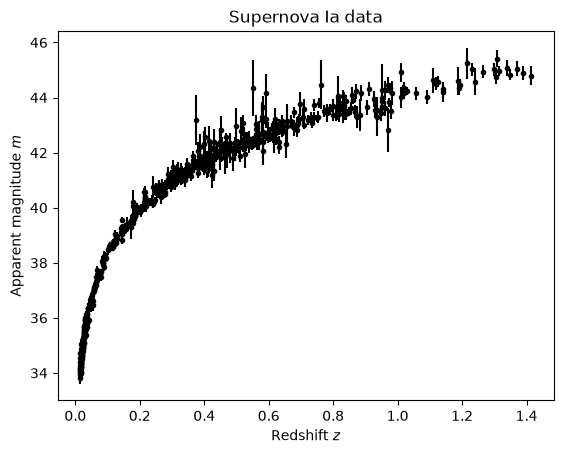

In [6]:
fig, ax = plt.subplots()
ax.title.set_text('Supernova Ia data')
# ax.errorbar(z_data, m_data, yerr=m_error, color="black", marker=".", linestyle="")
ax.errorbar(z_data, m_data, yerr=m_error, fmt='k.')
ax.set_xlabel('Redshift $z$')
ax.set_ylabel('Apparent magnitude $m$')

As a next step, try to implement a function to calculate the magnitude. You will need to integrate to get the luminosity distance, and you can follow the example outlined here

### b)

Define a function for calculating the distance moduli in your code, assuming a flat Universe. This function should depend on $\Omega_m$, the Hubble parameter $H_0$ and redshift $z$. Use the following for the definition of the distance modulus:

$$
\begin{aligned}
\mu &= m - M \\
&= 5\log_{10}\left(\frac{d_L}{10\,\mathrm{pc}}\right) \\
&= 5\log_{10}\left(\frac{d_L}{\mathrm{Mpc}}\right) + 25,
\end{aligned}
$$

where $d_L$ is the luminosity distance.

![1b](Problem1b.png)

In [8]:
from scipy.integrate import quad
from scipy import constants

def distance_modulus(redshift_z, omega_m, hubble_H0):
    """
    :param redshift_z: dimension 1
    :param omega_m: dimension 1
    :param hubble_H0: in unit (km/s)/Mpc
    :return: distance modulus (unitless)
    """
    c = constants.c / 1000      # to convert to km per s

    def E(z_prime):
        return np.sqrt(1 + omega_m * ((1 + z_prime)**3 - 1))


    def calculate_single(z):
        integral_result, integral_error = quad(
            lambda z_prime: 1 / E(z_prime),
            0,
            z
        )
        radial_comoving_distance = c / hubble_H0 * integral_result
        luminosity_distance = (1 + z) * radial_comoving_distance
        return 5 * np.log10(luminosity_distance) + 25

    redshift_z = np.asarray(redshift_z)

    if redshift_z.ndim == 0:
        return calculate_single(float(redshift_z))

    return np.array([
        calculate_single(z) for z in redshift_z.flat
    ]).reshape(redshift_z.shape)



### c)

Implement the $\chi^2$ as a function of $\Omega_m$ and $H_0$ according to its definition:

$$
\chi^2(\Omega_m, H_0)
= \sum_{i=1}^{N}
\frac{\left[\mu_i - \mu_{\mathrm{th}}(z_i,\Omega_m,H_0)\right]^2}{\sigma_i^2}.
$$

where $N$ is the number of data points, $\mu_i$ the observed distance modulus, $\mu_{\mathrm{th}}$ the theoretical model distance modulus which you computed above, $z_i$ the observed redshift, and $\sigma_i$ the error on the observed data.


Question: Why not use curvefit or another function directly, but define $\chi^2$ and then minimize?

In [11]:

def chi_squared(x):
    omega_m, hubble_H0 = x[0], x[1]
    return np.sum(np.square((m_data - distance_modulus(z_data, omega_m, hubble_H0)) / m_error))


### d)

Find the minimum of $\chi^2$ using a minimization algorithm of your choice (e.g. `scipy.optimize.minimize`) and report the values of $\Omega_m$ and $H_0$ that you find! **Tip:** Put reasonable bounds on your parameters!


In [60]:
from scipy.optimize import minimize

result = minimize(chi_squared, np.array((0.5, 70)), method='nelder-mead', bounds=((0.0, 2.0), (50, 100)))

print(f"Value of objective function at x (min Chi^2): {result.fun}")
print(f"x (omega_m, H0): {result.x}")



Value of objective function at x (min Chi^2): 562.9814977715837
x (omega_m, H0): [ 0.27904301 69.98682328]


### e)

Compare with a model where you fix $\Omega_m = 1$ during the minimization. What is the $\chi^2$ value now? Plot the two best fitting models and compare with the data!


In [61]:
from scipy.optimize import minimize

fixed_omega_m = 1.0

result_noDM = minimize(lambda H0: chi_squared(np.array((fixed_omega_m, H0[0]))), np.array((70, )), method='nelder-mead', bounds=((50, 100),))

print(f"Value of objective function at x (min Chi^2): {result_noDM.fun}")
print("Note that the value for Chi^2 is higher here (about double), i.e. the fit is worse.")
print(f"x (H0): {result_noDM.x}")


Value of objective function at x (min Chi^2): 1166.283110313867
Note that the value for Chi^2 is higher here (about double), i.e. the fit is worse.
x (H0): [63.17266083]


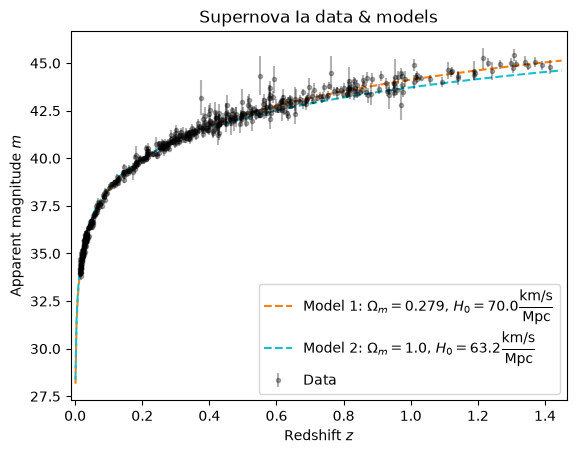

In [62]:

theory_z = np.linspace(0.001, 1.45, num=500)


fig, ax = plt.subplots()
ax.title.set_text('Supernova Ia data & models')
ax.set_xlabel('Redshift $z$')
ax.set_ylabel('Apparent magnitude $m$')

ax.plot(theory_z, distance_modulus(theory_z, result.x[0], result.x[1]), linestyle="dashed", color="tab:orange",
        label=rf"Model 1: $\Omega_m = {np.round(result.x[0], 3):.3}$, $H_0 = {np.round(result.x[1], 3):.3} "
              + r"\dfrac{\mathrm{km} / \mathrm{s}}{\mathrm{Mpc}}$")

ax.plot(theory_z, distance_modulus(theory_z, fixed_omega_m, result_noDM.x[0]), linestyle="dashed", color="tab:cyan",
        label=rf"Model 2: $\Omega_m = {fixed_omega_m:.3} $, $H_0 = {np.round(result_noDM.x[0], 3):.3} "
              + r"\dfrac{\mathrm{km} / \mathrm{s}}{\mathrm{Mpc}}$")

ax.errorbar(z_data, m_data, yerr=m_error, fmt='k.', label="Data", alpha=0.3)

ax.set_xmargin(0.01)

ax.legend()




### f)

Is the universe accelerating today?


We have assumed a flat universe, with a mass density and an astronmical constant $\Lambda$ for model 1 and without an astronomical constant for model 2. Model 1 is a better fit (smaller $\min \chi^2$). In both cases, we have assumed no radiation ($\Omega_r = 0$).

For model 1, the resulting $\Omega_m$ points to a positive cosmological constant. For this kind of universe, the scale factor is growing, first with $\ddot a < 0$ (decelerating), at later times with $\ddot a > 0$ (accelerating).

Acceleration begins for $\ddot a > 0 \Leftrightarrow \rho_m < 2 \rho_\Lambda$.

Taking the scaling behavior of both densities, we get $\rho_{m,0} \cdot a^{-3} < 2 \rho_{\Lambda,0}$ and therefore the universe starts accelerating from

$$
a_{\mathrm{acc}} = \left( \frac{\Omega_{m,0}}{2\Omega_{\Lambda,0}} \right)^{1/3}
$$

We can calculate our result here:


In [63]:
result_omega_m = result.x[0]
a_acc = (result_omega_m / (2 * (1 - result_omega_m))) ** (1/3)
print(a_acc)

0.5784208440583495


The result is about 0.58. We have defined the scaling factor today to be $a_0 = 1$, therefore we are already beyond this threshold and the universe is accelerating.


## Problem 2 - Age of the Universe

The oldest stars observed in the Universe have an age of approximately 13 Gyr (i.e. Creevey et al., 2014). We want to see what this implies for the cosmological parameters, since the Universe has to be at least as old as the oldest objects in it. The look-back time gives the age of the Universe, and in the lecture we derived

$$
t_0 = \frac{1}{H_0}\int_0^1
\frac{a\,da}{\sqrt{\Omega_m a + \Omega_K a^2 + \Omega_\Lambda a^4}}.
$$

As above, for this exercise we will assume

$$
H_0 = 70.0\;\mathrm{km\,s^{-1}\,Mpc^{-1}},
$$

this implies a Hubble time

$$
H_0^{-1} \approx 14.0\;\mathrm{Gyr}
$$

which you may use. Note that for this exercise, we will not assume that the Universe is flat.


Use again numerical integrations to calculate the age of the Universe as a function of the $\Omega$ parameters. Set up an array of ages, and use $\texttt{for}$ loops over $\Omega_m$ and $\Omega_\Lambda$ to fill it. Once you have the array, you can use the $\texttt{contour}$ function of matplotlib to visualise your results.

### (i)

Implement a function to calculate the age of the Universe with the parameters $\Omega_m$, $\Omega_\Lambda$. Note that these two determine the value of $\Omega_K$.



### (ii)

Calculate the age of the Universe for a grid of values

$$
\Omega_m \in [0,1]
\qquad\text{and}\qquad
\Omega_\Lambda \in [-0.2,1].
$$

Present your results using isochrones (contour lines of equal age), highlighting especially the ages

$$
[10,11,12,13,15,20,25]\;\mathrm{Gyr}.
$$

Note that not all Universes have a finite age.


### (iii)

What does the existence of the oldest stars imply for the allowed range of cosmological parameters? Can the universe be dominated by matter? What is the bound on $\Omega_m$ if we constrain ourselves to flat cosmological models?


### (iv)

Using `numpy.random.normal`, sample a thousand (`size=1000`) $\Omega_m$ values from a random distribution with mean (`loc`) of 0.28 and uncertainty (`scale`) 0.019 — this represents the constraints on $\Omega_m$ from a previous exercise. Calculate the age factor $H_0 \cdot t_0$ for each case, assuming a flat Universe.

If we want a Universe older than 13 Gyr not to be an outlier beyond 95% confidence (meaning less than 5% of the 1000 samples may be younger than 13 Gyr), what does this tell us for $H_0$?

**Tip:** Grid-based searches are easier to implement than optimization searches in this case.


In [ ]:
def age_universe(Omega_m, Omega_L):
    # implement the age function here
    result = 0.
    return result

Omega_m_array = np.linspace(0., 1., num=50)
Omega_L_array = np.linspace(-0.2, 1., num=50)

age_array = np.zeros((Omega_m_array.size,Omega_L_array.size))

for i, aux_Omega_Lambda in enumerate(Omega_L_array):
    for j, aux_Omega_m in enumerate(Omega_m_array):
        age_array[i, j] = age_universe(aux_Omega_m, aux_Omega_Lambda) # insert your age function here